# Inteligencia Artificial Avanzada

## Entrega 3 - Experimento 8: Fine-tuning con augmentation suave

**Estado: ejecutado y verificado.** Corrida `run_20260910_011506_334548_exp8_fine_tuning_mobilenetv2_augmentation_suave`: 34 epocas, mejor checkpoint 22; accuracy test 77,25 %, macro-F1 77,25 %, loss 0,7044. Mejora validacion frente al 6 (val_loss 0,7122 vs 0,7512), con un acierto menos en test (618 vs 619). No demuestra superioridad estadistica. Las salidas guardadas corresponden a esta corrida.

Se compara con la configuracion del Experimento 6: mismo modelo inicial entrenado
del Exp. 5, mismas 3.200 fotografias y particiones, MobileNetV2 desde
`block_16_expand`, BatchNormalization congelada y LR inicial `1e-5`.
El unico cambio experimental es augmentation suave durante el fine-tuning:
reflexion horizontal aleatoria y rotacion de hasta 10,8 grados. No se aplica
Object Detection, segmentacion, zoom ni cambios de color.

Hipotesis: estas variaciones pueden reducir el sobreajuste sin eliminar estructuras
botanicas. Una mejora no esta garantizada; el resultado negativo del Exp. 3 no
evalua esta combinacion de red preentrenada y transformaciones moderadas.

### Ejecucion independiente en Colab

1. Seleccionar un entorno con GPU y ejecutar las celdas en orden desde el inicio.
2. La celda 3 espera en `MyDrive/2026_IAA_GrupoC` los tres archivos de la misma
   corrida 5: `modelo_exp5.keras`, `metricas_entrega3_exp5.json` y `manifest_splits.csv`.
   Cambiar solo `SOURCE_DIR` si estan en otra carpeta. No cargar pesos del 6 o del 7.
3. Conservar `dataset_raw` en Drive. Si falta una foto, se intenta recuperar su URL
   original; no se solicitan observaciones nuevas ni se descartan filas.
4. Los resultados se escriben en una unica carpeta fechada dentro de
   `artifacts_entrega3/runs`; las imagenes de trabajo quedan en `/content/iaa_work`.
   No se guardan copias del dataset aumentado en Drive. El guardado `.keras`
   esta comentado en 13.1.
5. El checkpoint se selecciona por `val_loss`. La celda 10.4 exporta la evaluacion
   de validacion. Ejecutar test una vez para documentar la configuracion fijada,
   no para ajustar parametros repetidamente.



In [1]:
#@title 1. Configuracion general

EXPERIMENT_NUMBER = 8
EXPERIMENT_ID = "exp8_fine_tuning_mobilenetv2_augmentation_suave"
EXPERIMENT_TITLE = "Exp. 8 - Fine-tuning MobileNetV2 + augmentation suave"
USE_OBJECT_DETECTION = False


SEED = 42 #@param {type:"integer"}
MAX_IMAGES_PER_SPECIES = 400 #@param {type:"integer"}
MIN_IMAGES_RECOMMENDED = 100 #@param {type:"integer"}

IMG_SIZE = 224 #@param {type:"integer"}
BATCH_SIZE = 32 #@param {type:"integer"}
EPOCHS = 200 #@param {type:"integer"}
LEARNING_RATE = 0.00001 #@param {type:"number"}
FINE_TUNE_FROM = "block_16_expand"
EARLY_STOPPING_PATIENCE = 12
REDUCE_LR_PATIENCE = 4
MIN_LEARNING_RATE = 1e-7
AUGMENTATION_ROTATION_FACTOR = 0.03
AUGMENTATION_FLIP_MODE = "horizontal"

TEST_FRACTION = 0.25
VAL_FRACTION_TOTAL = 0.15
TRAIN_FRACTION_TOTAL = 0.60

USE_GOOGLE_DRIVE = True #@param {type:"boolean"}
FORCE_REDOWNLOAD = False #@param {type:"boolean"}

# La condicion nativa/exotica se determina por catalogo regional.
RESTRICT_OBSERVATIONS_TO_BA = False #@param {type:"boolean"}
print("Experimento:", EXPERIMENT_NUMBER, "-", EXPERIMENT_TITLE)
print(f"Split objetivo: train={TRAIN_FRACTION_TOTAL:.0%}, val={VAL_FRACTION_TOTAL:.0%}, test={TEST_FRACTION:.0%}")


Experimento: 8 - Exp. 8 - Fine-tuning MobileNetV2 + augmentation suave
Split objetivo: train=60%, val=15%, test=25%


In [2]:
#@title 2. Librerias y reproducibilidad

import os
import hashlib
import platform
import re
import io
import json
import time
import shutil
import random
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import requests
from tqdm.auto import tqdm

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)



def slugify_species(name):
    return re.sub(r"[^A-Za-z0-9]+", "_", str(name).strip()).strip("_")

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

def dataset_partition_sha256(frame):
    import hashlib
    columns = ["observation_id", "photo_id", "scientific_name", "condition_ba", "split"]
    data = frame[columns].astype(str).copy()
    data["scientific_name"] = data["scientific_name"].map(
        lambda value: re.sub(r"[^a-z0-9]+", "_", value.strip().casefold()).strip("_")
    )
    records = sorted(data.values.tolist())
    payload = json.dumps(records, ensure_ascii=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


TensorFlow: 2.20.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
#@title 3. Directorios y archivos originales del Experimento 5

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/gdrive', force_remount=False)
    BASE_DIR = Path('/content/gdrive/MyDrive/2026_IAA_GrupoC')
else:
    BASE_DIR = Path('/content/2026_IAA_GrupoC')



RAW_DIR = BASE_DIR / "dataset_raw"
MANIFEST_PATH = BASE_DIR / "manifest_inaturalist.csv"

ARTIFACTS_ROOT = BASE_DIR / "artifacts_entrega3"
RESULTS_ROOT = ARTIFACTS_ROOT / "runs"
RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
RUN_NAME = f"run_{RUN_TIMESTAMP}_{EXPERIMENT_ID}"
RUN_DIR = RESULTS_ROOT / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=False)
ARTIFACTS_DIR = RUN_DIR

WORK_DIR = Path("/content/iaa_work") / RUN_NAME
WORK_DIR.mkdir(parents=True, exist_ok=False)
CROP_SPLIT_DIR = WORK_DIR / "dataset_sin_recorte"

BALANCED_MANIFEST_PATH = RUN_DIR / "manifest_balanceado.csv"
SPLIT_MANIFEST_PATH = RUN_DIR / "manifest_splits.csv"
CROP_MANIFEST_PATH = RUN_DIR / "manifest_splits_object_detection_crop.csv"

RAW_DIR.mkdir(parents=True, exist_ok=True)
print("Resultados en Drive:", RUN_DIR)
print("Imagenes temporales en Colab:", WORK_DIR)

# Editar solo esta carpeta: debe contener los tres archivos de la MISMA corrida 5.
SOURCE_DIR = BASE_DIR
SOURCE_MODEL_PATH = SOURCE_DIR / "modelo_exp5.keras"
SOURCE_METRICS_PATH = SOURCE_DIR / "metricas_entrega3_exp5.json"
SOURCE_MANIFEST_PATH = SOURCE_DIR / "manifest_splits.csv"
for path in [SOURCE_MODEL_PATH, SOURCE_METRICS_PATH, SOURCE_MANIFEST_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Falta archivo del Exp. 5: {path}")
source_metrics = json.loads(SOURCE_METRICS_PATH.read_text(encoding="utf-8"))
if source_metrics.get("experiment_id") != "exp5_transfer_learning_mobilenetv2":
    raise ValueError("Las metricas no corresponden al Exp. 5.")
if source_metrics.get("object_detection_enabled"):
    raise ValueError("Se requiere el Exp. 5 sin Object Detection.")
if IMG_SIZE != source_metrics["img_size"]:
    raise ValueError("La resolucion debe coincidir con el Exp. 5.")
EXPECTED_SOURCE_CLASSES = ['Cortaderia_selloana', 'Erythrina_crista-galli', 'Gleditsia_triacanthos', 'Iris_pseudacorus', 'Ligustrum_lucidum', 'Melia_azedarach', 'Passiflora_caerulea', 'Phytolacca_dioica']
if source_metrics.get("classes") != EXPECTED_SOURCE_CLASSES:
    raise ValueError("El orden y los nombres de clases no coinciden con el modelo 5 verificado.")
reference = pd.read_csv(SOURCE_MANIFEST_PATH, dtype={"observation_id": str, "photo_id": str})
required = ["observation_id", "photo_id", "scientific_name", "condition_ba", "split", "local_path"]
if not set(required).issubset(reference.columns):
    raise ValueError("El manifiesto del Exp. 5 no tiene las columnas requeridas.")
if reference[required].isna().any().any() or reference["observation_id"].duplicated().any():
    raise ValueError("El manifiesto del Exp. 5 contiene faltantes o duplicados.")
if reference["photo_id"].duplicated().any():
    raise ValueError("Una fotografia del Exp. 5 aparece mas de una vez.")
expected_run = "run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2"
expected_partition_hash = "40e8690e3867c1d19efd28795f6e58f78b9e9e60896ef68ae7dc0e4cd3e1def6"
expected_model_hash = "80a97412d1f9599d223d86aa750eb33097f6c412a70e67d6f646169ca349b412"

if source_metrics.get("run_name") != expected_run:
    raise ValueError("Las metricas pertenecen a otra corrida del Exp. 5.")

if dataset_partition_sha256(reference) != expected_partition_hash:
    raise ValueError("El manifiesto no coincide con las particiones originales del Exp. 5.")

actual_model_hash = hashlib.sha256(SOURCE_MODEL_PATH.read_bytes()).hexdigest()
if actual_model_hash != expected_model_hash:
    raise ValueError("El modelo no coincide con el archivo verificado del Exp. 5.")

print("Modelo y particiones del Exp. 5 verificados.")
if set(reference["split"]) != {"train", "val", "test"}:
    raise ValueError("Particiones invalidas en el manifiesto del Exp. 5.")
for split in ["train", "val", "test"]:
    if int((reference["split"] == split).sum()) != source_metrics["n_" + split]:
        raise ValueError(f"Cantidad incompatible con las metricas del Exp. 5: {split}")

def source_species_key(value):
    return re.sub(r"[^a-z0-9]+", "_", str(value).strip().casefold()).strip("_")

source_class_by_key = {source_species_key(c): c for c in source_metrics["classes"]}
if len(source_class_by_key) != len(source_metrics["classes"]):
    raise ValueError("Clases ambiguas en las metricas del Exp. 5.")
if set(reference["scientific_name"].map(source_species_key)) != set(source_class_by_key):
    raise ValueError("Especies incompatibles entre manifiesto y metricas del Exp. 5.")

def partition_signature(frame):
    columns = ["observation_id", "photo_id", "scientific_name", "condition_ba", "split"]
    selected = frame[columns].astype(str).copy()
    selected["scientific_name"] = selected["scientific_name"].map(source_species_key)
    return selected.sort_values(columns).reset_index(drop=True)

import hashlib
SOURCE_MODEL_SHA256 = hashlib.sha256(SOURCE_MODEL_PATH.read_bytes()).hexdigest()
if source_metrics.get("model_sha256") and SOURCE_MODEL_SHA256 != source_metrics["model_sha256"]:
    raise ValueError("El archivo .keras no corresponde al modelo 5 auditado.")
SOURCE_MANIFEST_SHA256 = hashlib.sha256(SOURCE_MANIFEST_PATH.read_bytes()).hexdigest()
reference.to_csv(RUN_DIR / "source_exp5_manifest_splits.csv", index=False)
print("Corrida de origen:", source_metrics["run_name"])


Mounted at /content/gdrive
Resultados en Drive: /content/gdrive/MyDrive/2026_IAA_GrupoC/artifacts_entrega3/runs/run_20260910_011506_334548_exp8_fine_tuning_mobilenetv2_augmentation_suave
Imagenes temporales en Colab: /content/iaa_work/run_20260910_011506_334548_exp8_fine_tuning_mobilenetv2_augmentation_suave
Modelo y particiones del Exp. 5 verificados.
Corrida de origen: run_20260908_144525_973750_exp5_transfer_learning_mobilenetv2


## 4. Catálogo inicial de especies

Para la prueba de concepto se trabaja con **8 clases visuales**. La lista está pensada para ser suficientemente acotada para la Entrega 2 y, al mismo tiempo, permitir evaluar un problema multiclase real.


In [4]:
#@title 4.1 Catálogo de especies del prototipo

SPECIES_CATALOG = pd.DataFrame([

    {
        "scientific_name": "Erythrina crista-galli",
        "common_name": "Ceibo",
        "condition_ba": "Nativa",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Passiflora caerulea",
        "common_name": "Mburucuyá",
        "condition_ba": "Nativa",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Cortaderia selloana",
        "common_name": "Cortadera",
        "condition_ba": "Nativa",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Phytolacca dioica",
        "common_name": "Ombú",
        "condition_ba": "Nativa",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Ligustrum lucidum",
        "common_name": "Ligustro",
        "condition_ba": "Exótica",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Gleditsia triacanthos",
        "common_name": "Acacia negra",
        "condition_ba": "Exótica",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Melia azedarach",
        "common_name": "Paraíso",
        "condition_ba": "Exótica",
        "status_source": "Flora Argentina",

    },

    {
        "scientific_name": "Iris pseudacorus",
        "common_name": "Lirio amarillo",
        "condition_ba": "Exótica",
        "status_source": "Flora Argentina",

    },

])

SPECIES_CATALOG["folder_name"] = (
    SPECIES_CATALOG["scientific_name"]
    .apply(slugify_species)
)

display(SPECIES_CATALOG)
print("\nCantidad de especies:", len(SPECIES_CATALOG))
print(SPECIES_CATALOG["condition_ba"].value_counts())


          scientific_name     common_name condition_ba    status_source  \
0  Erythrina crista-galli           Ceibo       Nativa  Flora Argentina   
1     Passiflora caerulea       Mburucuyá       Nativa  Flora Argentina   
2     Cortaderia selloana       Cortadera       Nativa  Flora Argentina   
3       Phytolacca dioica            Ombú       Nativa  Flora Argentina   
4       Ligustrum lucidum        Ligustro      Exótica  Flora Argentina   
5   Gleditsia triacanthos    Acacia negra      Exótica  Flora Argentina   
6         Melia azedarach         Paraíso      Exótica  Flora Argentina   
7        Iris pseudacorus  Lirio amarillo      Exótica  Flora Argentina   

              folder_name  
0  Erythrina_crista_galli  
1     Passiflora_caerulea  
2     Cortaderia_selloana  
3       Phytolacca_dioica  
4       Ligustrum_lucidum  
5   Gleditsia_triacanthos  
6         Melia_azedarach  
7        Iris_pseudacorus  


Cantidad de especies: 8
condition_ba
Nativa     4
Exótica    4
Name: count, dtype: int64


In [5]:
#@title 4.2 Validacion del catalogo regional

required_fields = [
    "scientific_name",
    "common_name",
    "condition_ba",
    "status_source",
    "folder_name"
]

missing_catalog_data = SPECIES_CATALOG[required_fields].isna().sum()

print("Campos faltantes:")
display(missing_catalog_data.to_frame("faltantes"))

print("\nCondiciones:")
display(
    SPECIES_CATALOG["condition_ba"]
    .value_counts()
    .rename("cantidad")
    .to_frame()
)

assert SPECIES_CATALOG["folder_name"].is_unique, "Los folder_name del catalogo deben ser unicos."


Campos faltantes:


                 faltantes
scientific_name          0
common_name              0
condition_ba             0
status_source            0
folder_name              0


Condiciones:


              cantidad
condition_ba          
Nativa               4
Exótica              4

## 5. Recuperar el dataset original del Experimento 5

Se usa su manifiesto, no una nueva consulta de observaciones a iNaturalist. Si falta una fotografia, se descarga la URL registrada para esa misma fotografia. Se conservan licencia, atribucion y coordenadas. No se debe usar el manifiesto de la corrida 6 descartada.


In [6]:
#@title 5.1 Recuperar fotografias por su URL original

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "UTN-FRBA-IAA-TP-Plantas/1.0 (academic prototype)"})

def download_image(url, out_path):
    """Descarga, valida y normaliza una imagen a JPEG RGB."""
    r = SESSION.get(url, timeout=45)
    r.raise_for_status()
    img = Image.open(io.BytesIO(r.content)).convert('RGB')
    if min(img.size) < 80:
        raise ValueError(f'Imagen demasiado pequeña: {img.size}')
    out_path.parent.mkdir(parents=True, exist_ok=True)
    img.save(out_path, format='JPEG', quality=92)


In [7]:
#@title 5.2 Recuperar exactamente las fotografias del Experimento 5

if FORCE_REDOWNLOAD:
    raise ValueError("Fine-tuning no permite reconstruir el dataset consultando observaciones nuevas.")
manifest = reference.copy()
files_by_name = {}
for path in RAW_DIR.rglob("*.jpg"):
    files_by_name.setdefault(path.name, path)
resolved = []
for row in tqdm(manifest.itertuples(index=False), total=len(manifest)):
    filename = f"obs_{row.observation_id}_photo_{row.photo_id}.jpg"
    original = Path(row.local_path)
    candidate = original if original.name == filename and original.is_file() else files_by_name.get(filename)
    if candidate is None:
        folder = source_class_by_key[source_species_key(row.scientific_name)]
        candidate = RAW_DIR / folder / filename
        if not hasattr(row, "photo_url") or pd.isna(row.photo_url):
            raise FileNotFoundError(f"Falta la foto original y su URL: {filename}")
        download_image(row.photo_url, candidate)
    resolved.append(str(candidate))
manifest["local_path"] = resolved
manifest["folder_name"] = manifest["scientific_name"].map(
    lambda name: source_class_by_key[source_species_key(name)]
)
print("Se recuperaron las fotografias originales del Exp. 5:", len(manifest))


  0%|          | 0/3200 [00:00<?, ?it/s]

Se recuperaron las fotografias originales del Exp. 5: 3200


Archivos faltantes: 0


                        cantidad
scientific_name                 
Cortaderia selloana          400
Erythrina crista-galli       400
Gleditsia triacanthos        400
Iris pseudacorus             400
Ligustrum lucidum            400
Melia azedarach              400
Passiflora caerulea          400
Phytolacca dioica            400

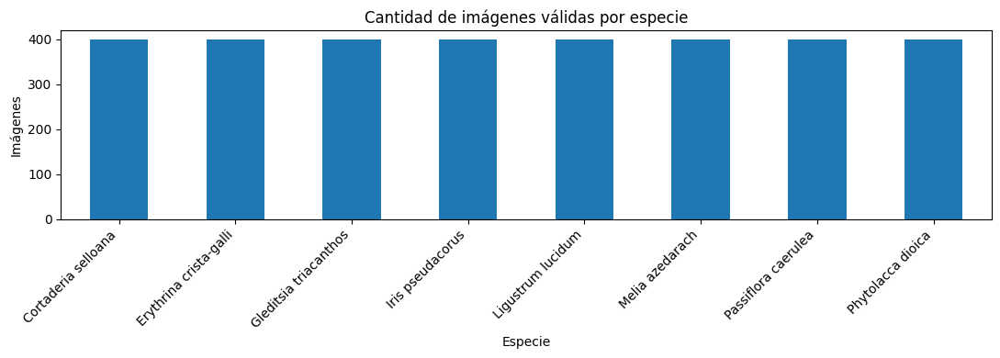

/tmp/ipykernel_2052/11898717.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(n_per_class, len(x)), random_state=SEED))


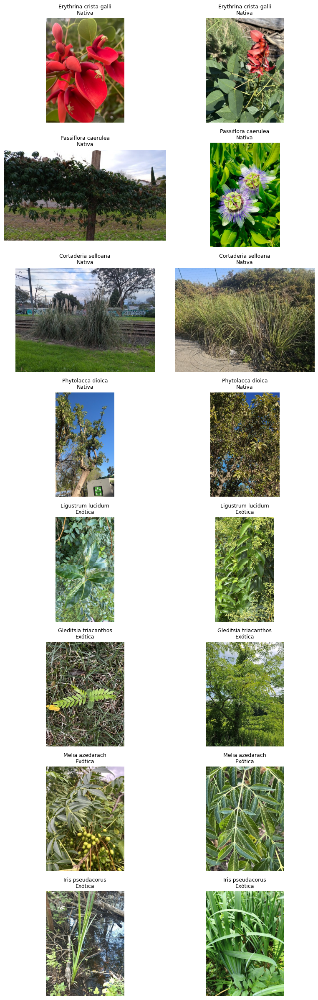

In [8]:
#@title 6. Auditar dataset: archivos, cantidades y ejemplos

# Verifica que los archivos realmente existan.
manifest["file_exists"] = manifest["local_path"].apply(lambda p: Path(p).exists())
missing = (~manifest["file_exists"]).sum()
print("Archivos faltantes:", missing)

manifest = manifest[manifest["file_exists"]].copy()

counts = manifest["scientific_name"].value_counts().sort_index()
display(counts.rename("cantidad").to_frame())

plt.figure(figsize=(11, 4))
counts.plot(kind="bar")
plt.title("Cantidad de imágenes válidas por especie")
plt.ylabel("Imágenes")
plt.xlabel("Especie")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Muestra 2 ejemplos por especie.
n_per_class = 2
sample_df = (
    manifest.groupby("scientific_name", group_keys=False)
            .apply(lambda x: x.sample(min(n_per_class, len(x)), random_state=SEED))
            .reset_index(drop=True)
)

fig, axes = plt.subplots(len(SPECIES_CATALOG), n_per_class, figsize=(8, 3 * len(SPECIES_CATALOG)))
if len(SPECIES_CATALOG) == 1:
    axes = np.array([axes])

for ax in np.array(axes).reshape(-1):
    ax.axis("off")

for i, (_, row) in enumerate(sample_df.iterrows()):
    species_idx = list(SPECIES_CATALOG["scientific_name"]).index(row["scientific_name"])
    pos_in_species = sum(sample_df.iloc[:i]["scientific_name"] == row["scientific_name"])
    ax = axes[species_idx, pos_in_species]
    img = Image.open(row["local_path"])
    ax.imshow(img)
    ax.set_title(f"{row['scientific_name']}\n{row['condition_ba']}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

if counts.min() < MIN_IMAGES_RECOMMENDED:
    warnings.warn(
        f"La clase con menos imágenes tiene {counts.min()}. "
        "Conviene revisar la lista de especies o aumentar la descarga."
    )


## 7. Seleccion y particiones inmutables del Experimento 5

No se vuelve a muestrear ni a dividir el dataset. Se reutilizan los identificadores de observacion y fotografia, especies, condiciones y particiones del manifiesto original del 5. La comparacion se repite antes de entrenar sobre el manifiesto de imagenes preparadas; cualquier diferencia es un error fatal.


In [9]:
#@title 7.1 Conservar la seleccion original del Experimento 5

balanced = manifest.copy()
pd.testing.assert_frame_equal(partition_signature(reference), partition_signature(balanced))
balanced.to_csv(BALANCED_MANIFEST_PATH, index=False)
display(balanced.groupby("scientific_name").size().rename("cantidad"))


scientific_name
Cortaderia selloana       400
Erythrina crista-galli    400
Gleditsia triacanthos     400
Iris pseudacorus          400
Ligustrum lucidum         400
Melia azedarach           400
Passiflora caerulea       400
Phytolacca dioica         400
Name: cantidad, dtype: int64

In [10]:
#@title 7.2 Reutilizar las particiones originales del Experimento 5

split_manifest = balanced.copy()
pd.testing.assert_frame_equal(partition_signature(reference), partition_signature(split_manifest))
train_df = split_manifest[split_manifest["split"] == "train"].copy()
val_df = split_manifest[split_manifest["split"] == "val"].copy()
test_df = split_manifest[split_manifest["split"] == "test"].copy()
split_manifest.to_csv(SPLIT_MANIFEST_PATH, index=False)
display(pd.crosstab(split_manifest["scientific_name"], split_manifest["split"]))


split                   test  train  val
scientific_name                         
Cortaderia selloana      100    240   60
Erythrina crista-galli   100    240   60
Gleditsia triacanthos    100    240   60
Iris pseudacorus         100    240   60
Ligustrum lucidum        100    240   60
Melia azedarach          100    240   60
Passiflora caerulea      100    240   60
Phytolacca dioica        100    240   60

In [11]:
#@title 7.3 Auditoría cuantitativa del dataset

# ============================================================
# Distribución por especie y split
# ============================================================

audit_species = pd.crosstab(
    split_manifest["scientific_name"],
    split_manifest["split"]
)

# Orden deseado
for col in ["train", "val", "test"]:
    if col not in audit_species.columns:
        audit_species[col] = 0

audit_species = audit_species[
    ["train", "val", "test"]
]

audit_species["total"] = audit_species.sum(axis=1)

print("Distribución por especie:")
display(audit_species)


# ============================================================
# Distribución por condición regional
# ============================================================

audit_condition = pd.crosstab(
    split_manifest["condition_ba"],
    split_manifest["split"]
)

for col in ["train", "val", "test"]:
    if col not in audit_condition.columns:
        audit_condition[col] = 0

audit_condition = audit_condition[
    ["train", "val", "test"]
]

audit_condition["total"] = audit_condition.sum(axis=1)

print("\nDistribución por condición:")
display(audit_condition)


# ============================================================
# Resumen general
# ============================================================

dataset_summary = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Validación", "Prueba", "Total"],
    "Cantidad": [
        len(train_df),
        len(val_df),
        len(test_df),
        len(split_manifest)
    ]
})

dataset_summary["Porcentaje"] = (
    dataset_summary["Cantidad"] /
    len(split_manifest) * 100
)

# El total debe mostrarse como 100%
dataset_summary.loc[
    dataset_summary["Conjunto"] == "Total",
    "Porcentaje"
] = 100

print("\nResumen del dataset:")
display(dataset_summary)


# ============================================================
# Validaciones automáticas
# ============================================================

print("\nControles:")

print(
    "Cantidad de especies:",
    split_manifest["scientific_name"].nunique()
)

print(
    "Cantidad de condiciones:",
    split_manifest["condition_ba"].nunique()
)

print(
    "Duplicados observation_id:",
    split_manifest["observation_id"].duplicated().sum()
)

print(
    "Duplicados local_path:",
    split_manifest["local_path"].duplicated().sum()
)


# Verifica que una observación no haya quedado en más de un split
obs_split_count = (
    split_manifest
    .groupby("observation_id")["split"]
    .nunique()
)

leakage_count = (obs_split_count > 1).sum()

print(
    "Observaciones presentes en más de un split:",
    leakage_count
)


if leakage_count == 0:
    print("✅ No se detectó leakage por observation_id.")
else:
    print("⚠️ Revisar separación del dataset.")


# ============================================================
# Guardar tablas
# ============================================================

audit_species.to_csv(
    ARTIFACTS_DIR / "auditoria_especies_split.csv"
)

audit_condition.to_csv(
    ARTIFACTS_DIR / "auditoria_condicion_split.csv"
)

dataset_summary.to_csv(
    ARTIFACTS_DIR / "auditoria_resumen_dataset.csv",
    index=False
)

if leakage_count or split_manifest["observation_id"].duplicated().any():
    raise ValueError("Observaciones duplicadas o compartidas entre particiones.")


Distribución por especie:


split                   train  val  test  total
scientific_name                                
Cortaderia selloana       240   60   100    400
Erythrina crista-galli    240   60   100    400
Gleditsia triacanthos     240   60   100    400
Iris pseudacorus          240   60   100    400
Ligustrum lucidum         240   60   100    400
Melia azedarach           240   60   100    400
Passiflora caerulea       240   60   100    400
Phytolacca dioica         240   60   100    400


Distribución por condición:


split         train  val  test  total
condition_ba                         
Exótica         960  240   400   1600
Nativa          960  240   400   1600


Resumen del dataset:


        Conjunto  Cantidad  Porcentaje
0  Entrenamiento      1920        60.0
1     Validación       480        15.0
2         Prueba       800        25.0
3          Total      3200       100.0


Controles:
Cantidad de especies: 8
Cantidad de condiciones: 2
Duplicados observation_id: 0
Duplicados local_path: 0
Observaciones presentes en más de un split: 0
✅ No se detectó leakage por observation_id.


## 8. Preparacion de imagenes completas

No se utiliza detector ni recorte. Se conserva el procesamiento del 5: conversion RGB, recodificacion JPEG calidad 92 y posterior redimensionado a 224 x 224. Los nombres de archivos con `crop` y `object_detection` se conservan para compatibilidad con los resultados historicos, no indican deteccion activa.

No se generan figuras comparativas de recortes. Se conservan los manifiestos necesarios para el procesamiento y la trazabilidad.


In [12]:
#@title 8.1 Preparacion sin detector

assert not USE_OBJECT_DETECTION
print("Se usaran imagenes completas, sin detector ni recorte central.")


Se usaran imagenes completas, sin detector ni recorte central.


In [13]:
#@title 8.2 Preparar imagen completa RGB

def crop_image_with_detector(source_path, output_path):
    # Conserva la recodificacion JPEG de las corridas originales sin detector.
    with Image.open(source_path) as source_image:
        img = source_image.convert("RGB")
    output_path.parent.mkdir(parents=True, exist_ok=True)
    img.save(output_path, format="JPEG", quality=92)
    return {
        "crop_path": str(output_path),
        "crop_method": "full_image_fallback",
        "detected": False,
        "detection_score": None,
        "detection_class_id": None,
        "detection_class_name": None,
        "crop_x1": 0, "crop_y1": 0,
        "crop_x2": img.width, "crop_y2": img.height,
        "source_width": img.width, "source_height": img.height,
    }


In [14]:
#@title 8.3 Generar imagenes preparadas de esta corrida

def crop_split_dataset(split_manifest):
    if CROP_SPLIT_DIR.exists():
        shutil.rmtree(CROP_SPLIT_DIR)

    records = []
    for row in tqdm(split_manifest.itertuples(index=False), total=len(split_manifest)):
        source_path = Path(row.local_path)
        dst = CROP_SPLIT_DIR / row.split / row.folder_name / source_path.name
        base_record = row._asdict()

        try:
            crop_info = crop_image_with_detector(source_path, dst)
            base_record.update(crop_info)
            base_record["crop_error"] = None
            records.append(base_record)
        except Exception as e:
            base_record["crop_path"] = None
            base_record["crop_method"] = "error"
            base_record["detected"] = False
            base_record["detection_score"] = None
            base_record["detection_class_id"] = None
            base_record["detection_class_name"] = None
            base_record["crop_error"] = f"{type(e).__name__}: {str(e)[:160]}"
            records.append(base_record)

    cropped_manifest = pd.DataFrame(records)
    if cropped_manifest["crop_path"].isna().any():
        raise RuntimeError("Fallo la preparacion de imagenes. Corregir el error; no se permite descartar muestras.")
    cropped_manifest.to_csv(CROP_MANIFEST_PATH, index=False)
    print("Imagenes completas preparadas en:", CROP_SPLIT_DIR)
    return cropped_manifest


cropped_manifest = crop_split_dataset(split_manifest)

print("\nResumen de preparacion (sin recortes):")
display(cropped_manifest["crop_method"].value_counts().rename("cantidad").to_frame())

crop_detection_rate = float(cropped_manifest["detected"].mean()) if len(cropped_manifest) else 0.0
print(f"Tasa de deteccion usada para recorte: {crop_detection_rate:.2%}")

cropped_manifest.to_csv(ARTIFACTS_DIR / "manifest_splits_object_detection_crop.csv", index=False)


  0%|          | 0/3200 [00:00<?, ?it/s]

Imagenes completas preparadas en: /content/iaa_work/run_20260910_011506_334548_exp8_fine_tuning_mobilenetv2_augmentation_suave/dataset_sin_recorte

Resumen de preparacion (sin recortes):


                     cantidad
crop_method                  
full_image_fallback      3200

Tasa de deteccion usada para recorte: 0.00%


## 9. Carga de imagenes

Las imagenes completas se cargan en RGB. El orden de clases se fija explicitamente con las metricas originales del 5; no se reordena la salida del modelo por variantes ortograficas. Validacion y prueba no se barajan.

La celda 9.3 define las transformaciones y genera una vista previa. Solo 10.2 las aplica al dataset de entrenamiento. Validacion y test no cambian.


In [15]:
#@title 9.1 Crear datasets TensorFlow desde imagenes preparadas

train_crop_df = cropped_manifest[cropped_manifest["split"] == "train"].copy()
val_crop_df = cropped_manifest[cropped_manifest["split"] == "val"].copy()
test_crop_df = cropped_manifest[cropped_manifest["split"] == "test"].copy()

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    CROP_SPLIT_DIR / "train",
    labels="inferred",
    class_names=list(source_metrics["classes"]),
    label_mode="categorical",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    CROP_SPLIT_DIR / "val",
    labels="inferred",
    class_names=list(source_metrics["classes"]),
    label_mode="categorical",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    CROP_SPLIT_DIR / "test",
    labels="inferred",
    class_names=list(source_metrics["classes"]),
    label_mode="categorical",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False
)

CLASS_NAMES = train_ds_raw.class_names
NUM_CLASSES = len(CLASS_NAMES)

print("\nClases detectadas:")
for i, c in enumerate(CLASS_NAMES):
    print(i, "->", c)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds_raw.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds_raw.cache().prefetch(AUTOTUNE)
test_ds = test_ds_raw.cache().prefetch(AUTOTUNE)

TEST_FILE_PATHS = list(test_ds_raw.file_paths)
crop_lookup = cropped_manifest.set_index("crop_path").to_dict(orient="index")


Found 1920 files belonging to 8 classes.
Found 480 files belonging to 8 classes.
Found 800 files belonging to 8 classes.

Clases detectadas:
0 -> Cortaderia_selloana
1 -> Erythrina_crista-galli
2 -> Gleditsia_triacanthos
3 -> Iris_pseudacorus
4 -> Ligustrum_lucidum
5 -> Melia_azedarach
6 -> Passiflora_caerulea
7 -> Phytolacca_dioica


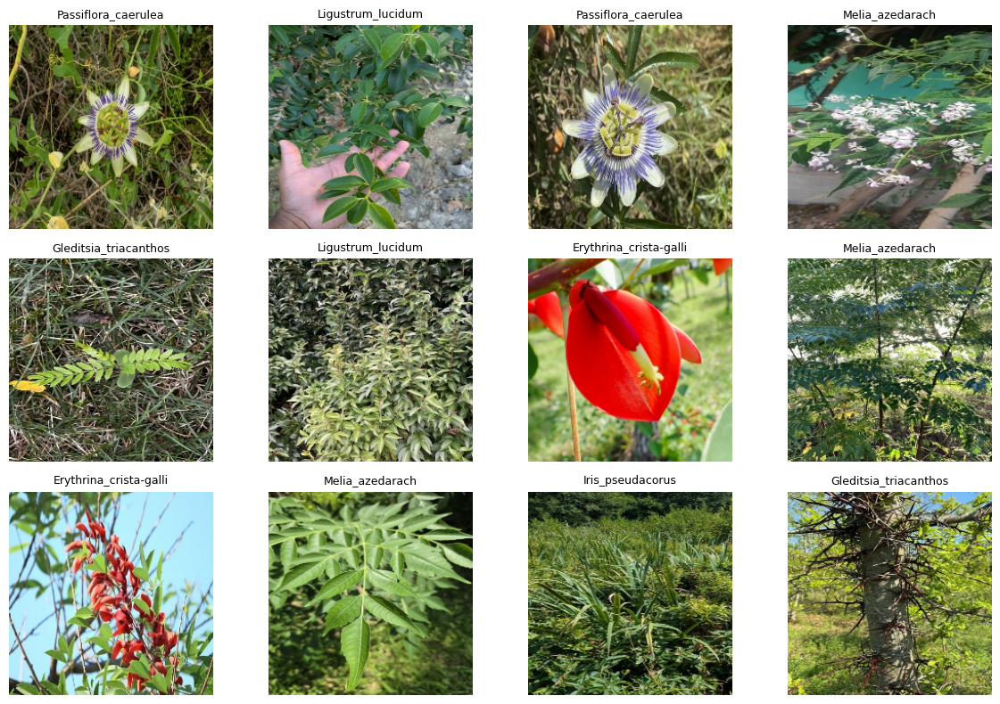

In [16]:
#@title 9.2 Visualizar un batch de entrenamiento

images_batch, labels_batch = next(iter(train_ds))

plt.figure(figsize=(12, 8))
for i in range(min(12, len(images_batch))):
    ax = plt.subplot(3, 4, i + 1)
    plt.imshow(images_batch[i].numpy().astype("uint8"))
    class_idx = int(np.argmax(labels_batch[i].numpy()))
    plt.title(CLASS_NAMES[class_idx], fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()


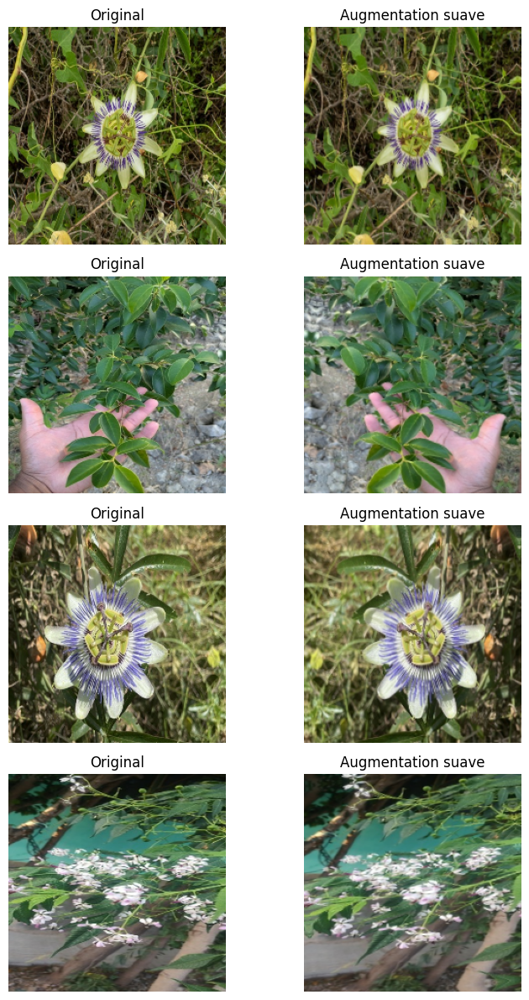

In [17]:
#@title 9.3 Augmentation suave: definicion y ejemplos para el informe

def make_augmentation(seed):
    return keras.Sequential([
        layers.RandomFlip(AUGMENTATION_FLIP_MODE, seed=seed),
        layers.RandomRotation(
            AUGMENTATION_ROTATION_FACTOR, fill_mode="reflect",
            interpolation="bilinear", seed=seed + 1
        ),
    ], name="augmentation_suave")

# La vista previa usa otro generador y reutiliza el batch de 9.2.
preview_augmentation = make_augmentation(SEED + 1000)
preview_images = images_batch[:4]
preview_augmented = preview_augmentation(preview_images, training=True)
assert preview_augmented.shape == preview_images.shape
assert bool(tf.reduce_all(tf.math.is_finite(preview_augmented)))
np.testing.assert_allclose(
    preview_augmentation(preview_images, training=False).numpy(), preview_images.numpy()
)
fig, axes = plt.subplots(len(preview_images), 2, figsize=(8, 3 * len(preview_images)), squeeze=False)
for i in range(len(preview_images)):
    for j, batch in enumerate([preview_images, preview_augmented]):
        axes[i, j].imshow(np.clip(batch[i].numpy(), 0, 255).astype("uint8"))
        axes[i, j].set_title("Original" if j == 0 else "Augmentation suave")
        axes[i, j].axis("off")
fig.tight_layout()
fig.savefig(RUN_DIR / "ejemplos_augmentation_suave.png", dpi=160, bbox_inches="tight")
plt.show()


## 10. Fine-tuning parcial

Se carga el modelo completo del 5 sin el optimizador anterior. Se entrena su clasificador y el bloque final de MobileNetV2 desde `block_16_expand`, sin actualizar BatchNormalization. La normalizacion [-1, 1] ya pertenece al modelo guardado: no se aplica otra vez. Se verifican las particiones completas antes de cargar los pesos.


In [18]:
#@title 10.1 Verificar particiones, cargar Exp. 5 y preparar fine-tuning

if list(CLASS_NAMES) != list(source_metrics["classes"]):
    raise ValueError("El orden de clases debe coincidir exactamente con las salidas del modelo 5.")
pd.testing.assert_frame_equal(partition_signature(reference), partition_signature(split_manifest))
pd.testing.assert_frame_equal(partition_signature(reference), partition_signature(cropped_manifest))
if hashlib.sha256(SOURCE_MODEL_PATH.read_bytes()).hexdigest() != SOURCE_MODEL_SHA256:
    raise ValueError("El modelo de origen cambio durante la preparacion.")

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

# Recuperar el modelo entrenado, sin reutilizar el optimizador anterior.
model = keras.models.load_model(str(SOURCE_MODEL_PATH), compile=False)
if model.output_shape[-1] != NUM_CLASSES:
    raise ValueError("Cantidad de salidas incompatible con las clases del Exp. 5.")
base_model = model.get_layer("mobilenetv2_1.00_224")
base_model.trainable = True

start = [layer.name for layer in base_model.layers].index(FINE_TUNE_FROM)

# Ajustar el bloque final, manteniendo BatchNormalization congelada.
for i, layer in enumerate(base_model.layers):
    layer.trainable = (
        i >= start
        and not isinstance(layer, layers.BatchNormalization)
    )

optimizer = keras.optimizers.Adam(learning_rate=LEARNING_RATE)
model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

assert len(base_model.trainable_weights) > 0
assert all(not layer.trainable for layer in base_model.layers
           if isinstance(layer, layers.BatchNormalization))
assert model.input_shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
print("Modelo cargado:", SOURCE_MODEL_PATH)
print("Learning rate inicial:", LEARNING_RATE)
model.summary()


Modelo cargado: /content/gdrive/MyDrive/2026_IAA_GrupoC/modelo_exp5.keras
Learning rate inicial: 1e-05


Model: "Exp5_MobileNetV2"


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_img (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocessing (Rescaling)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤

 Total params: 2,422,984 (9.24 MB)


 Trainable params: 1,044,040 (3.98 MB)


 Non-trainable params: 1,378,944 (5.26 MB)


In [19]:
from itertools import zip_longest

print("Modelo de origen:", source_metrics.get("experiment_id"))
print("Carpeta de imagenes:", CROP_SPLIT_DIR)
print("\nIndice | Clase del modelo 5 | Clase cargada en el 8")

for i, (original, actual) in enumerate(
    zip_longest(source_metrics["classes"], CLASS_NAMES)
):
    print(f"{i}: {original!r} | {actual!r}")


Modelo de origen: exp5_transfer_learning_mobilenetv2
Carpeta de imagenes: /content/iaa_work/run_20260910_011506_334548_exp8_fine_tuning_mobilenetv2_augmentation_suave/dataset_sin_recorte

Indice | Clase del modelo 5 | Clase cargada en el 6
0: 'Cortaderia_selloana' | 'Cortaderia_selloana'
1: 'Erythrina_crista-galli' | 'Erythrina_crista-galli'
2: 'Gleditsia_triacanthos' | 'Gleditsia_triacanthos'
3: 'Iris_pseudacorus' | 'Iris_pseudacorus'
4: 'Ligustrum_lucidum' | 'Ligustrum_lucidum'
5: 'Melia_azedarach' | 'Melia_azedarach'
6: 'Passiflora_caerulea' | 'Passiflora_caerulea'
7: 'Phytolacca_dioica' | 'Phytolacca_dioica'


In [20]:
#@title 10.2 Entrenar modelo

callbacks = [
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=REDUCE_LR_PATIENCE,
        min_lr=MIN_LEARNING_RATE,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=EARLY_STOPPING_PATIENCE,
        restore_best_weights=True,
        verbose=1
    )
]

# Crear una instancia nueva tras cargar el modelo y fijar las semillas en 10.1.
train_augmentation = make_augmentation(SEED)

def augment_train_batch(images, labels):
    augmented = train_augmentation(images, training=True)
    augmented = tf.clip_by_value(augmented, 0.0, 255.0)
    augmented = tf.ensure_shape(augmented, images.shape)
    return augmented, labels

# El cache esta ANTES de la transformacion aleatoria: no congela las variaciones.
# Val y test conservan sus datasets originales sin augmentation.
train_ds_augmented = train_ds.map(augment_train_batch, num_parallel_calls=1).prefetch(AUTOTUNE)

history = model.fit(
    train_ds_augmented,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df["phase"] = "fine_tuning_augmentation_suave"
history_df.to_csv(RUN_DIR / "history_entrenamiento.csv", index=False)
best_epoch = int(history_df.loc[history_df["val_loss"].idxmin(), "epoch"])
print("Epocas realmente ejecutadas:", len(history_df))
print("Pesos restaurados de la mejor epoca por val_loss:", best_epoch)


Epoch 1/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 41s 311ms/step - accuracy: 0.8198 - loss: 0.5074 - val_accuracy: 0.7292 - val_loss: 0.7421 - learning_rate: 1.0000e-05
Epoch 2/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 14s 232ms/step - accuracy: 0.8307 - loss: 0.4595 - val_accuracy: 0.7417 - val_loss: 0.7638 - learning_rate: 1.0000e-05
Epoch 3/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 14s 232ms/step - accuracy: 0.8604 - loss: 0.4172 - val_accuracy: 0.7292 - val_loss: 0.7495 - learning_rate: 1.0000e-05
Epoch 4/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 14s 234ms/step - accuracy: 0.8557 - loss: 0.4224 - val_accuracy: 0.7375 - val_loss: 0.7514 - learning_rate: 1.0000e-05
Epoch 5/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 14s 233ms/step - accuracy: 0.8573 - loss: 0.4144 - val_accuracy: 0.7479 - val_loss: 0.7386 - learning_rate: 1.0000e-05
Epoch 6/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 14s 233ms/step - accuracy: 0.8438 - loss: 0.4319 - val_accuracy: 0.7458 - val_loss: 0.7367 - learning_rate: 1.0000e-05
Epoch 7/200
60/60 ━━━━━━━━━━━━━━━━━━━━ 14s 231ms/ste

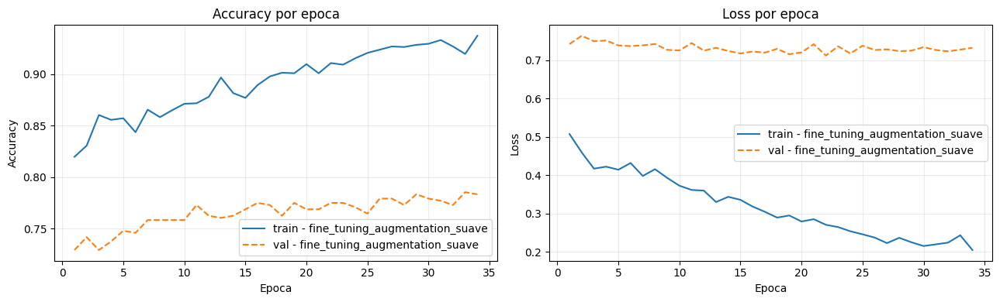

In [21]:
#@title 10.3 Curvas de entrenamiento y validacion

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for phase_name, phase_df in history_df.groupby("phase", sort=False):
    ax[0].plot(phase_df["epoch"], phase_df["accuracy"], label=f"train - {phase_name}")
    ax[0].plot(phase_df["epoch"], phase_df["val_accuracy"], linestyle="--", label=f"val - {phase_name}")
    ax[1].plot(phase_df["epoch"], phase_df["loss"], label=f"train - {phase_name}")
    ax[1].plot(phase_df["epoch"], phase_df["val_loss"], linestyle="--", label=f"val - {phase_name}")

ax[0].set_title("Accuracy por epoca")
ax[0].set_xlabel("Epoca")
ax[0].set_ylabel("Accuracy")
ax[0].legend()
ax[0].grid(alpha=0.25)

ax[1].set_title("Loss por epoca")
ax[1].set_xlabel("Epoca")
ax[1].set_ylabel("Loss")
ax[1].legend()
ax[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

fig.savefig(ARTIFACTS_DIR / "curvas_entrenamiento.png", dpi=160, bbox_inches="tight")
history_df.to_csv(ARTIFACTS_DIR / "history_entrenamiento.csv", index=False)


In [22]:
#@title 10.4 Evaluacion de validacion del checkpoint seleccionado

validation_loss, validation_accuracy = model.evaluate(val_ds, verbose=1)
val_prob = model.predict(val_ds, verbose=1)
val_true = np.argmax(np.concatenate([y.numpy() for _, y in val_ds], axis=0), axis=1)
val_pred = np.argmax(val_prob, axis=1)
validation_macro_f1 = float(f1_score(val_true, val_pred, labels=np.arange(NUM_CLASSES), average="macro"))
validation_summary = {
    "selection_monitor": "val_loss",
    "best_epoch": int(history_df.loc[history_df["val_loss"].idxmin(), "epoch"]),
    "loss": float(validation_loss),
    "species_accuracy": float(validation_accuracy),
    "species_macro_f1": validation_macro_f1,
    "augmentation_applied": False,
}
(RUN_DIR / "metricas_validacion.json").write_text(
    json.dumps(validation_summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
validation_results = pd.DataFrame({
    "image_path": list(val_ds_raw.file_paths),
    "real_species": [CLASS_NAMES[i] for i in val_true],
    "pred_species": [CLASS_NAMES[i] for i in val_pred],
    "confidence": np.max(val_prob, axis=1),
})
validation_results.to_csv(RUN_DIR / "resultados_validacion.csv", index=False)
print(json.dumps(validation_summary, indent=2))


15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7750 - loss: 0.7122
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step
{
  "selection_monitor": "val_loss",
  "best_epoch": 22,
  "loss": 0.7121626734733582,
  "species_accuracy": 0.7749999761581421,
  "species_macro_f1": 0.7764999777929603,
  "augmentation_applied": false
}


## 11. Evaluacion del prototipo

Se evalúan **dos niveles**:

### A. Identificación de especie
Problema multiclase de 8 clases.

### B. Condición nativa/exótica
Se deriva a partir de la especie predicha.  
Esto permite separar correctamente el problema visual del conocimiento botánico regional.


In [23]:
#@title 11.1 Evaluacion global en prueba

test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")


25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.7725 - loss: 0.7044

Test loss: 0.7044
Test accuracy: 0.7725


In [24]:
#@title 11.2 Predicciones y metricas por especie

y_true_onehot = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_true = np.argmax(y_true_onehot, axis=1)

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)
y_conf = np.max(y_prob, axis=1)

species_report = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

species_report_df = pd.DataFrame(species_report).T
display(species_report_df)

species_macro_f1 = f1_score(y_true, y_pred, average="macro")
species_accuracy = accuracy_score(y_true, y_pred)

print(f"Accuracy especie: {species_accuracy:.4f}")
print(f"Macro-F1 especie: {species_macro_f1:.4f}")

species_report_df.to_csv(ARTIFACTS_DIR / "classification_report_especies.csv")


25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step


                        precision  recall  f1-score   support
Cortaderia_selloana      0.884615  0.9200  0.901961  100.0000
Erythrina_crista-galli   0.835052  0.8100  0.822335  100.0000
Gleditsia_triacanthos    0.702128  0.6600  0.680412  100.0000
Iris_pseudacorus         0.914286  0.9600  0.936585  100.0000
Ligustrum_lucidum        0.752809  0.6700  0.708995  100.0000
Melia_azedarach          0.631068  0.6500  0.640394  100.0000
Passiflora_caerulea      0.867470  0.7200  0.786885  100.0000
Phytolacca_dioica        0.632000  0.7900  0.702222  100.0000
accuracy                 0.772500  0.7725  0.772500    0.7725
macro avg                0.777428  0.7725  0.772474  800.0000
weighted avg             0.777428  0.7725  0.772474  800.0000

Accuracy especie: 0.7725
Macro-F1 especie: 0.7725


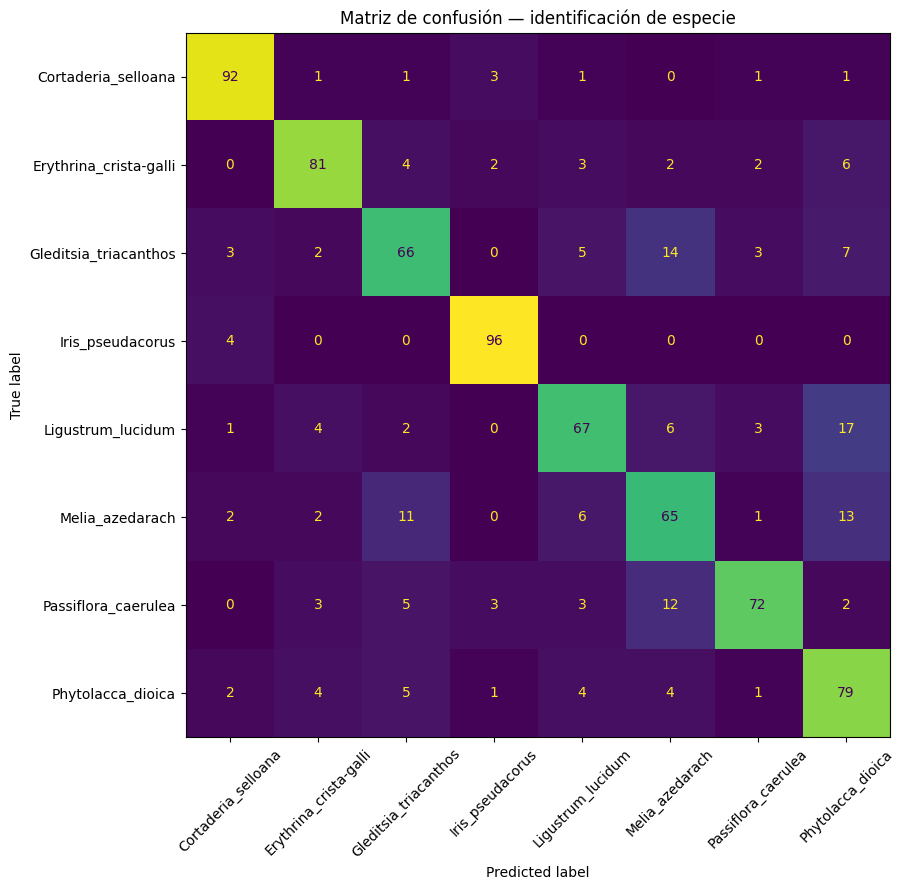

In [25]:
#@title 11.3 Matriz de confusion por especie

cm_species = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 9))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_species,
    display_labels=CLASS_NAMES
)
disp.plot(ax=ax, xticks_rotation=45, values_format="d", colorbar=False)
plt.title("Matriz de confusión — identificación de especie")
plt.tight_layout()
plt.show()

fig.savefig(ARTIFACTS_DIR / "matriz_confusion_especies.png", dpi=170, bbox_inches="tight")


In [26]:
#@title 11.4 Evaluar clasificacion derivada Nativa / Exotica

import re
import unicodedata

def normalize_species_name(value):
    text = unicodedata.normalize("NFKD", str(value).strip().casefold())
    text = "".join(c for c in text if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", "_", text).strip("_")

catalog = SPECIES_CATALOG.copy()
catalog["_species_key"] = catalog["scientific_name"].map(normalize_species_name)
if catalog["_species_key"].duplicated().any():
    raise ValueError("Especies duplicadas al normalizar el catalogo.")
catalog_by_key = catalog.set_index("_species_key")
class_to_condition = {}
for class_name in CLASS_NAMES:
    key = normalize_species_name(class_name)
    if key not in catalog_by_key.index:
        raise KeyError(f"Clase sin correspondencia regional: {class_name!r}")
    condition = catalog_by_key.loc[key, "condition_ba"]
    if condition not in ["Nativa", "Exótica"]:
        raise ValueError(f"Condicion regional invalida: {class_name!r}")
    class_to_condition[class_name] = condition

true_species_names = [CLASS_NAMES[i] for i in y_true]
pred_species_names = [CLASS_NAMES[i] for i in y_pred]

y_true_condition = np.array([class_to_condition[s] for s in true_species_names])
y_pred_condition = np.array([class_to_condition[s] for s in pred_species_names])

condition_labels = ["Nativa", "Exótica"]

condition_report = classification_report(
    y_true_condition,
    y_pred_condition,
    labels=condition_labels,
    output_dict=True,
    zero_division=0
)

condition_report_df = pd.DataFrame(condition_report).T
display(condition_report_df)

condition_accuracy = accuracy_score(y_true_condition, y_pred_condition)
condition_macro_f1 = f1_score(
    y_true_condition,
    y_pred_condition,
    labels=condition_labels,
    average="macro"
)

print(f"Accuracy condición: {condition_accuracy:.4f}")
print(f"Macro-F1 condición: {condition_macro_f1:.4f}")

condition_report_df.to_csv(ARTIFACTS_DIR / "classification_report_condicion.csv")


              precision   recall  f1-score    support
Nativa         0.848411  0.86750  0.857849  400.00000
Exótica        0.864450  0.84500  0.854614  400.00000
accuracy       0.856250  0.85625  0.856250    0.85625
macro avg      0.856430  0.85625  0.856232  800.00000
weighted avg   0.856430  0.85625  0.856232  800.00000

Accuracy condición: 0.8562
Macro-F1 condición: 0.8562


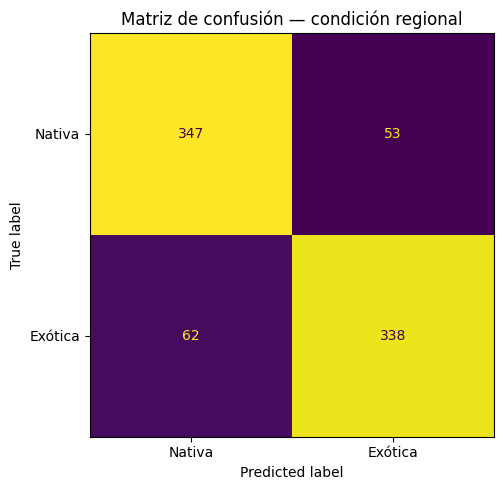

In [27]:
#@title 11.5 Matriz de confusion Nativa / Exotica

cm_condition = confusion_matrix(
    y_true_condition,
    y_pred_condition,
    labels=condition_labels
)

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_condition,
    display_labels=condition_labels
)
disp.plot(ax=ax, values_format="d", colorbar=False)
plt.title("Matriz de confusión — condición regional")
plt.tight_layout()
plt.show()

fig.savefig(ARTIFACTS_DIR / "matriz_confusion_condicion.png", dpi=170, bbox_inches="tight")


In [28]:
#@title 11.6 Tabla de resultados de prueba

source_paths = []
crop_methods = []
detection_scores = []

for crop_path in TEST_FILE_PATHS:
    info = crop_lookup.get(crop_path, {})
    source_paths.append(info.get("local_path", crop_path))
    crop_methods.append(info.get("crop_method", "unknown"))
    detection_scores.append(info.get("detection_score", None))

results_test = pd.DataFrame({
    "crop_path": TEST_FILE_PATHS,
    "source_path": source_paths,
    "crop_method": crop_methods,
    "detection_score": detection_scores,
    "real_species": true_species_names,
    "pred_species": pred_species_names,
    "confidence": y_conf,
    "real_condition": y_true_condition,
    "pred_condition": y_pred_condition,
})

results_test["species_correct"] = results_test["real_species"] == results_test["pred_species"]
results_test["condition_correct"] = results_test["real_condition"] == results_test["pred_condition"]

display(results_test.head(20))

results_test.to_csv(ARTIFACTS_DIR / "resultados_test.csv", index=False)

print("\nErrores de especie:", int((~results_test["species_correct"]).sum()))
print("Errores de condicion:", int((~results_test["condition_correct"]).sum()))


                                            crop_path  \
0   /content/iaa_work/run_20260910_011506_334548_e...   
1   /content/iaa_work/run_20260910_011506_334548_e...   
2   /content/iaa_work/run_20260910_011506_334548_e...   
3   /content/iaa_work/run_20260910_011506_334548_e...   
4   /content/iaa_work/run_20260910_011506_334548_e...   
5   /content/iaa_work/run_20260910_011506_334548_e...   
6   /content/iaa_work/run_20260910_011506_334548_e...   
7   /content/iaa_work/run_20260910_011506_334548_e...   
8   /content/iaa_work/run_20260910_011506_334548_e...   
9   /content/iaa_work/run_20260910_011506_334548_e...   
10  /content/iaa_work/run_20260910_011506_334548_e...   
11  /content/iaa_work/run_20260910_011506_334548_e...   
12  /content/iaa_work/run_20260910_011506_334548_e...   
13  /content/iaa_work/run_20260910_011506_334548_e...   
14  /content/iaa_work/run_20260910_011506_334548_e...   
15  /content/iaa_work/run_20260910_011506_334548_e...   
16  /content/iaa_work/run_20260


Errores de especie: 182
Errores de condicion: 115


## 12. Analisis de errores


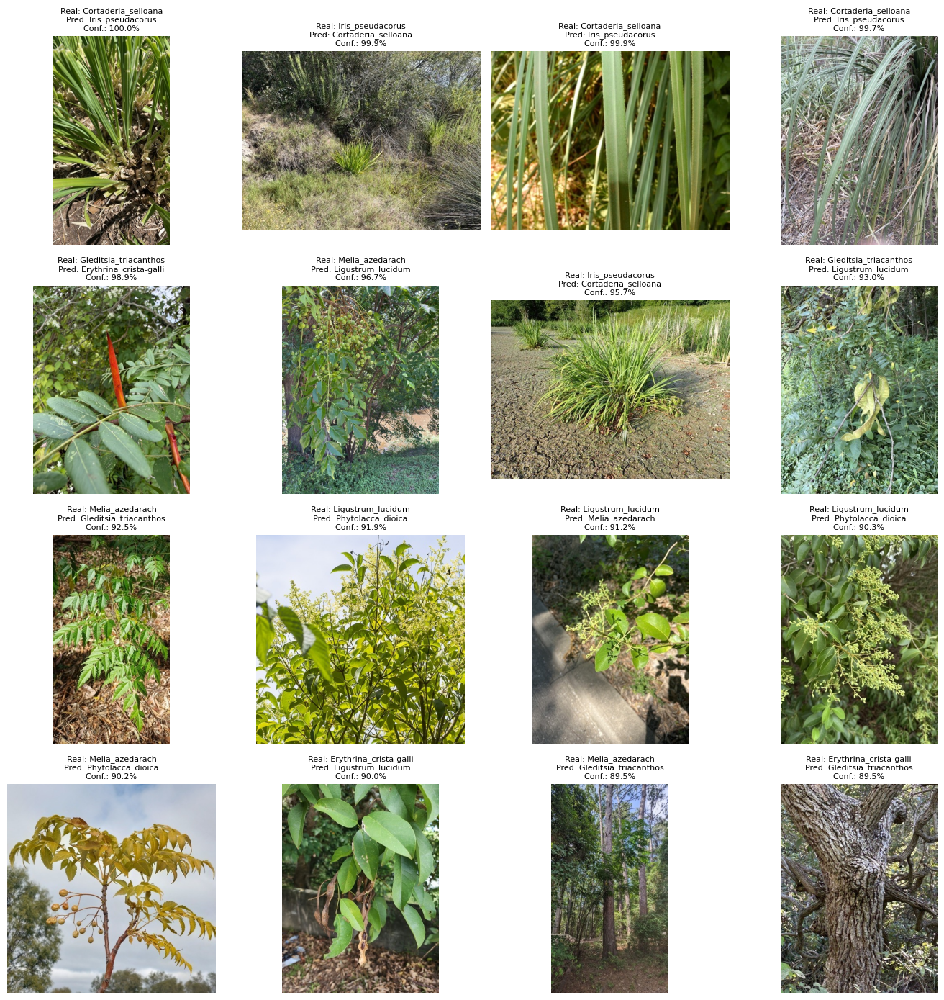

In [29]:
#@title 12.1 Mostrar errores de clasificacion mas confiados

errors_df = results_test[~results_test["species_correct"]].copy()
errors_df = errors_df.sort_values("confidence", ascending=False)

N_ERRORS_TO_SHOW = min(16, len(errors_df))

if N_ERRORS_TO_SHOW == 0:
    print("No hubo errores de especie en el conjunto de prueba.")
else:
    cols = 4
    rows = int(np.ceil(N_ERRORS_TO_SHOW / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 3.5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, errors_df.head(N_ERRORS_TO_SHOW).iterrows()):
        img = Image.open(row["crop_path"])
        ax.imshow(img)
        ax.set_title(
            f"Real: {row['real_species']}\n"
            f"Pred: {row['pred_species']}\n"
            f"Conf.: {row['confidence']:.1%}",
            fontsize=8
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    fig.savefig(ARTIFACTS_DIR / "errores_representativos.png", dpi=160, bbox_inches="tight")


In [30]:
#@title 12.2 Resumen de pares de confusion

if len(errors_df):
    confusion_pairs = (
        errors_df.groupby(["real_species", "pred_species"])
                 .size()
                 .rename("cantidad")
                 .reset_index()
                 .sort_values("cantidad", ascending=False)
    )
    display(confusion_pairs.head(20))
else:
    print("Sin pares de confusión para mostrar.")


              real_species            pred_species  cantidad
24       Ligustrum_lucidum       Phytolacca_dioica        17
15   Gleditsia_triacanthos         Melia_azedarach        14
30         Melia_azedarach       Phytolacca_dioica        13
35     Passiflora_caerulea         Melia_azedarach        12
27         Melia_azedarach   Gleditsia_triacanthos        11
17   Gleditsia_triacanthos       Phytolacca_dioica         7
28         Melia_azedarach       Ligustrum_lucidum         6
22       Ligustrum_lucidum         Melia_azedarach         6
11  Erythrina_crista-galli       Phytolacca_dioica         6
39       Phytolacca_dioica   Gleditsia_triacanthos         5
14   Gleditsia_triacanthos       Ligustrum_lucidum         5
32     Passiflora_caerulea   Gleditsia_triacanthos         5
42       Phytolacca_dioica         Melia_azedarach         4
38       Phytolacca_dioica  Erythrina_crista-galli         4
6   Erythrina_crista-galli   Gleditsia_triacanthos         4
41       Phytolacca_dioi

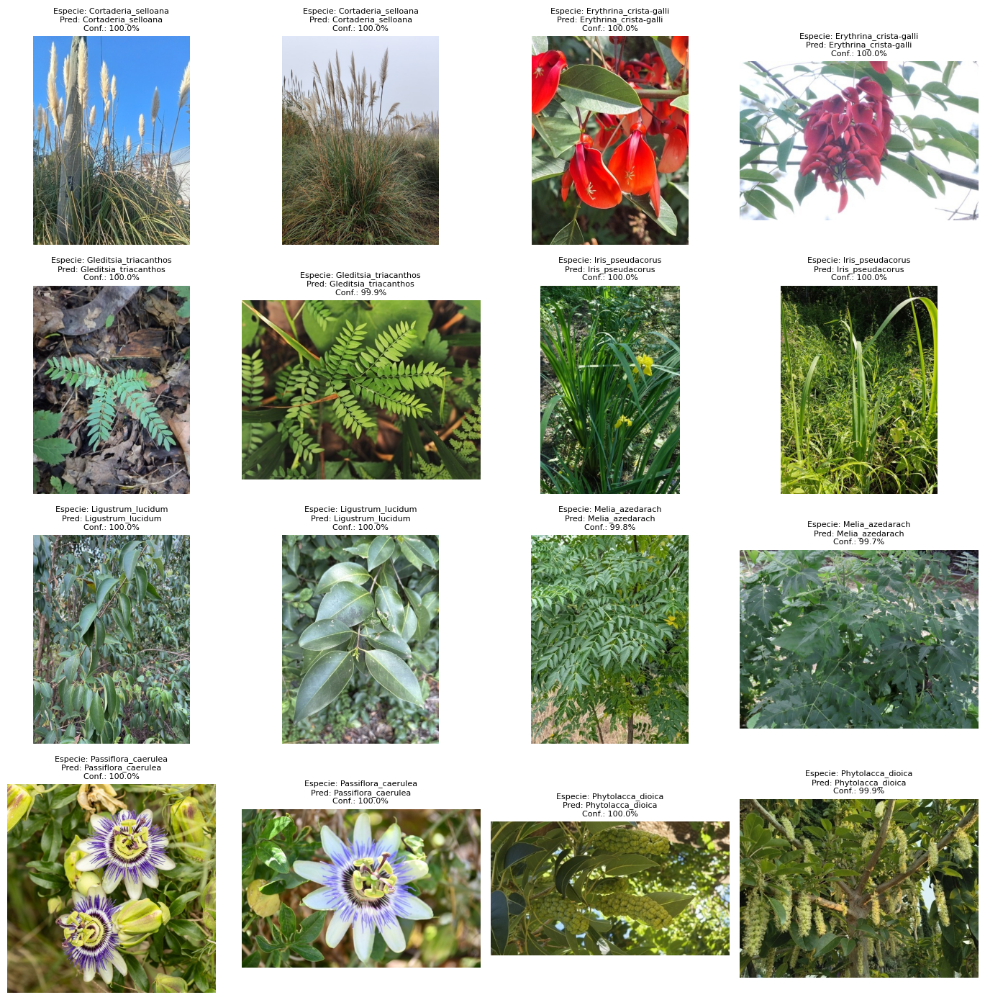

In [31]:
#@title 12.3 Mostrar 2 aciertos de clasificacion por especie

N_CORRECT_PER_SPECIES = 2
correct_df = results_test[results_test["species_correct"]].copy()
correct_df = correct_df.sort_values("confidence", ascending=False)

selected_examples = []
for species in CLASS_NAMES:
    species_df = correct_df[correct_df["real_species"] == species].head(N_CORRECT_PER_SPECIES)
    selected_examples.append(species_df)

selected_df = pd.concat(selected_examples, ignore_index=True) if selected_examples else pd.DataFrame()

if selected_df.empty:
    print("No hubo aciertos de especie en el conjunto de prueba.")
else:
    cols = 4
    rows = int(np.ceil(len(selected_df) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 3.5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, selected_df.iterrows()):
        img = Image.open(row["crop_path"])
        ax.imshow(img)
        ax.set_title(
            f"Especie: {row['real_species']}\n"
            f"Pred: {row['pred_species']}\n"
            f"Conf.: {row['confidence']:.1%}",
            fontsize=8
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    fig.savefig(ARTIFACTS_DIR / "aciertos_2_por_especie.png", dpi=160, bbox_inches="tight")


## 13. Exportacion directa a runs

Se guardan metricas y predicciones de validacion y test, historial, probabilidades
de test, reportes por clase, manifiestos, auditorias, lista de capas entrenables,
resumen del modelo, matrices CSV y PNG, curvas y ejemplos de errores/aciertos.
Tambien se exporta una vista previa de augmentation, no figuras de recortes.
El JSON registra transformaciones, callbacks, semillas y origen del modelo.

Todos los archivos se guardan una sola vez en la carpeta fechada de `runs`.
Repetir la celda 3 crea otra corrida; repetir 13.1 actualiza la actual.
El guardado `.keras` esta comentado por tamano. No se necesita exportar el modelo
8 para evaluar esta corrida. Para reproducirla se necesitan los tres archivos del 5.


In [32]:
#@title 13.1 Exportar metricas, tablas e imagenes EN GOOGLE DRIVE



best_val_loss_epoch = None
if "val_loss" in history_df.columns and len(history_df):
    best_val_loss_epoch = int(history_df.loc[history_df["val_loss"].idxmin(), "epoch"])

trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
non_trainable_params = int(np.sum([np.prod(v.shape) for v in model.non_trainable_weights]))
total_params = trainable_params + non_trainable_params

metrics_summary = {
    "run_name": RUN_NAME,
    "dataset_partition_sha256": dataset_partition_sha256(cropped_manifest),
    "timestamp": RUN_TIMESTAMP,
    "experiment_number": int(EXPERIMENT_NUMBER),
    "experiment_id": EXPERIMENT_ID,
    "experiment_title": EXPERIMENT_TITLE,
    "seed": int(SEED),
    "img_size": int(IMG_SIZE),
    "batch_size": int(BATCH_SIZE),
    "learning_rate": float(LEARNING_RATE),
    "epochs_configured": int(EPOCHS),
    "epochs_executed": int(len(history_df)),
    "best_val_loss_epoch": best_val_loss_epoch,
    "n_species": int(NUM_CLASSES),
    "n_train": int(len(train_crop_df)),
    "n_val": int(len(val_crop_df)),
    "n_test": int(len(test_crop_df)),
    "object_detection_enabled": bool(USE_OBJECT_DETECTION),
    "object_detection_model_url": None,
    "detection_class_ids": [],
    "detection_score_threshold": None,
    "crop_padding": None,
    "crop_detection_rate": float(crop_detection_rate),
    "crop_methods": cropped_manifest["crop_method"].value_counts().to_dict(),
    "base_classifier": "MobileNetV2",
    "pretrained_weights": "imagenet",
    "base_model_trainable": bool(base_model.trainable),
    "preprocessing": "RGB_0_255_a_menos1_1",
    "transfer_learning": True,
    "fine_tuning": True,
    "source_model_sha256": SOURCE_MODEL_SHA256,
    "source_manifest_sha256": SOURCE_MANIFEST_SHA256,
    "source_split_verified": True,
    "source_run": source_metrics["run_name"],
    "source_model_path": str(SOURCE_MODEL_PATH),
    "fine_tune_from": FINE_TUNE_FROM,
    "batch_normalization_frozen": True,
    "comparison_reference": "exp6_fine_tuning_mobilenetv2",
    "augmentation_enabled": True,
    "augmentation": {
        "scope": "train_only", "input_range": [0, 255],
        "flip_mode": AUGMENTATION_FLIP_MODE,
        "rotation_factor": AUGMENTATION_ROTATION_FACTOR,
        "rotation_degrees_max": AUGMENTATION_ROTATION_FACTOR * 360,
        "fill_mode": "reflect", "interpolation": "bilinear",
        "zoom": False, "color_changes": False,
        "seeds": [SEED, SEED + 1], "cache_before_augmentation": True,
    },
    "callbacks": {
        "monitor": "val_loss", "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "early_stopping_min_delta": 0, "restore_best_weights": True,
        "reduce_lr_patience": REDUCE_LR_PATIENCE, "reduce_lr_factor": 0.5,
        "reduce_lr_min_delta": 1e-4, "min_lr": MIN_LEARNING_RATE,
    },
    "validation": validation_summary,
    "best_val_loss": float(history_df["val_loss"].min()),
    "environment": {"python": platform.python_version(), "tensorflow": tf.__version__},
    "trainable_params": trainable_params,
    "non_trainable_params": non_trainable_params,
    "total_params": total_params,
    "test_loss": float(test_loss),
    "test_accuracy_metric": float(test_accuracy),
    "species_accuracy": float(species_accuracy),
    "species_macro_f1": float(species_macro_f1),
    "condition_accuracy": float(condition_accuracy),
    "condition_macro_f1": float(condition_macro_f1),
    "classes": list(CLASS_NAMES),
}

with open(RUN_DIR / f"metricas_entrega3_exp{EXPERIMENT_NUMBER}.json", "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, ensure_ascii=False, indent=2)

history_df.to_csv(RUN_DIR / "history_entrenamiento.csv", index=False)
pd.DataFrame(cm_species, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR / "matriz_confusion_especies.csv")
pd.DataFrame(cm_condition, index=condition_labels, columns=condition_labels).to_csv(RUN_DIR / "matriz_confusion_condicion.csv")
probabilities = pd.DataFrame(y_prob, columns=[f"prob_{name}" for name in CLASS_NAMES])
probabilities.insert(0, "crop_path", TEST_FILE_PATHS)
probabilities.to_csv(RUN_DIR / "probabilidades_test.csv", index=False)
trainable_layers = pd.DataFrame([
    {"layer": layer.name, "type": type(layer).__name__, "trainable": layer.trainable}
    for layer in base_model.layers
])
trainable_layers.to_csv(RUN_DIR / "capas_fine_tuning.csv", index=False)
results_test.to_csv(RUN_DIR / "resultados_test.csv", index=False)
species_report_df.to_csv(RUN_DIR / "classification_report_especies.csv")
condition_report_df.to_csv(RUN_DIR / "classification_report_condicion.csv")
cropped_manifest.to_csv(RUN_DIR / "manifest_splits_object_detection_crop.csv", index=False)

with open(RUN_DIR / "model_summary.txt", "w", encoding="utf-8") as f:
    model.summary(print_fn=lambda x: f.write(x + "\n"))

# El modelo .keras no se exporta por tamano. Descomentar solo si se necesita guardar pesos/modelo.
# MODEL_PATH = RUN_DIR / f"modelo_exp{EXPERIMENT_NUMBER}.keras"
# model.save(str(MODEL_PATH))


README_PATH = RUN_DIR / "README.txt"
with open(README_PATH, "w", encoding="utf-8") as f:
    f.write("IAA - Entrega 3 - Identificacion de especies vegetales\n")
    f.write("=" * 64 + "\n\n")
    f.write(f"Experimento: {EXPERIMENT_NUMBER} - {EXPERIMENT_TITLE}\n")
    f.write(f"Run: {RUN_NAME}\n")
    f.write(f"Resolucion: {IMG_SIZE}x{IMG_SIZE}\n")
    f.write(f"Batch size: {BATCH_SIZE}\n")
    f.write(f"Learning rate: {LEARNING_RATE}\n")
    f.write(f"Epocas ejecutadas: {len(history_df)}\n")
    f.write(f"Mejor epoca por val_loss: {best_val_loss_epoch}\n\n")
    f.write(f"Accuracy especie: {species_accuracy:.4f}\n")
    f.write(f"Macro-F1 especie: {species_macro_f1:.4f}\n")
    f.write(f"Accuracy condicion: {condition_accuracy:.4f}\n")
    f.write(f"Macro-F1 condicion: {condition_macro_f1:.4f}\n")
    f.write(f"Test loss: {test_loss:.4f}\n\n")
    f.write("Sin deteccion ni recortes. Augmentation suave solo en entrenamiento.\n")
    f.write("Nota: el modelo .keras no se exporta automaticamente por tamano.\n")

print("\nArchivos exportados en:")
print(RUN_DIR)
print("\nResumen:")
print(json.dumps(metrics_summary, ensure_ascii=False, indent=2))



Archivos exportados en:
/content/gdrive/MyDrive/2026_IAA_GrupoC/artifacts_entrega3/runs/run_20260910_011506_334548_exp8_fine_tuning_mobilenetv2_augmentation_suave

Resumen:
{
  "run_name": "run_20260910_011506_334548_exp8_fine_tuning_mobilenetv2_augmentation_suave",
  "dataset_partition_sha256": "40e8690e3867c1d19efd28795f6e58f78b9e9e60896ef68ae7dc0e4cd3e1def6",
  "timestamp": "20260910_011506_334548",
  "experiment_number": 8,
  "experiment_id": "exp8_fine_tuning_mobilenetv2_augmentation_suave",
  "experiment_title": "Exp. 8 - Fine-tuning MobileNetV2 + augmentation suave",
  "seed": 42,
  "img_size": 224,
  "batch_size": 32,
  "learning_rate": 1e-05,
  "epochs_configured": 200,
  "epochs_executed": 34,
  "best_val_loss_epoch": 22,
  "n_species": 8,
  "n_train": 1920,
  "n_val": 480,
  "n_test": 800,
  "object_detection_enabled": false,
  "object_detection_model_url": null,
  "detection_class_ids": [],
  "detection_score_threshold": null,
  "crop_padding": null,
  "crop_detection_rate